In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix,classification_report,r2_score
from sklearn.ensemble import RandomForestClassifier
from imblearn.combine import SMOTETomek
from joblib import dump

In [2]:
df = pd.read_excel("../Datasets/HIV_Dataset.xlsx")
df.head()

,Age,Sex,Fever,Fatigue,Skin_Rash,Night_Sweats,Muscle_Aches,Sore_Throat,Swollen_Lymph_Nodes,Headache,Diarrhea,Mouth_Ulcers,Unexplained_Weight_Loss,Persistent_Cough,Recurrent_Infections,Hemoglobin_g_dL,WBC_Count_10e9_L,CD4_Count_cells_uL,Viral_Load_copies_mL,HIV_Status
0,46,Female,0,1,0,0,0,0,1,0,0,0,0,0,1,13.2,7.13,273,17,1
1,60,Male,1,0,0,0,1,0,0,1,1,0,0,1,1,12.2,5.86,436,21,0
2,80,Male,0,0,0,0,0,0,0,0,1,0,0,1,0,12.6,6.87,763,8,0
3,31,Male,0,0,0,0,0,0,0,1,0,0,0,0,0,11.5,8.67,771,8,0
4,21,Male,0,0,0,0,0,0,0,1,1,0,0,0,0,16.3,7.62,1110,11,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      50000 non-null  int64  
 1   Sex                      50000 non-null  object 
 2   Fever                    50000 non-null  int64  
 3   Fatigue                  50000 non-null  int64  
 4   Skin_Rash                50000 non-null  int64  
 5   Night_Sweats             50000 non-null  int64  
 6   Muscle_Aches             50000 non-null  int64  
 7   Sore_Throat              50000 non-null  int64  
 8   Swollen_Lymph_Nodes      50000 non-null  int64  
 9   Headache                 50000 non-null  int64  
 10  Diarrhea                 50000 non-null  int64  
 11  Mouth_Ulcers             50000 non-null  int64  
 12  Unexplained_Weight_Loss  50000 non-null  int64  
 13  Persistent_Cough         50000 non-null  int64  
 14  Recurrent_Infections  

In [4]:
df.isna().sum()

Age                        0
Sex                        0
Fever                      0
Fatigue                    0
Skin_Rash                  0
Night_Sweats               0
Muscle_Aches               0
Sore_Throat                0
Swollen_Lymph_Nodes        0
Headache                   0
Diarrhea                   0
Mouth_Ulcers               0
Unexplained_Weight_Loss    0
Persistent_Cough           0
Recurrent_Infections       0
Hemoglobin_g_dL            0
WBC_Count_10e9_L           0
CD4_Count_cells_uL         0
Viral_Load_copies_mL       0
HIV_Status                 0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
for col in df.columns:
    print(df[col].unique(),col)
    print()

[46 60 80 31 21 40 37 22 49 50 71 62 47 59 36 27 51 74 52 53 61 56 20 63
 79 26 48 76 68 24 39 44 78 41 25 28 30 58 45 19 65 35 69 23 43 34 18 57
 67 66 75 32 42 55 70 33 38 72 64 54 77 73 29] Age

['Female' 'Male'] Sex

[0 1] Fever

[1 0] Fatigue

[0 1] Skin_Rash

[0 1] Night_Sweats

[0 1] Muscle_Aches

[0 1] Sore_Throat

[1 0] Swollen_Lymph_Nodes

[0 1] Headache

[0 1] Diarrhea

[0 1] Mouth_Ulcers

[0 1] Unexplained_Weight_Loss

[0 1] Persistent_Cough

[1 0] Recurrent_Infections

[13.2 12.2 12.6 11.5 16.3 13.6 14.6 13.4  8.  13.1 13.3 14.8 10.5 12.1
 13.  15.3 11.1 11.8 12.8 14.9 13.7 14.7 12.5 13.5 12.4 12.7 14.5 10.7
 15.5 12.9 16.7 15.2 15.6 11.9  9.8 17.1 14.2 13.8 12.  15.9 17.4 15.
 14.  11.3 11.4 12.3 14.3 14.4 16.1 13.9 11.  14.1 16.  11.6 10.  16.5
 17.   8.9 15.4 15.8 15.7 16.4 10.9 11.7 10.6 16.8 10.1 10.4 11.2 17.3
 16.6  9.5  7.  10.2 16.2  9.6 15.1  7.5 10.8 10.3  9.1  9.3 18.  16.9
  9.9 17.5  7.2  9.4 17.8 17.2 17.7 18.5  9.7 17.9 18.2  9.   7.9 18.1
  8.4  8.7  8.1 1

In [7]:
df['HIV_Status'].value_counts(normalize=True) * 100

HIV_Status
0    60.0
1    40.0
Name: proportion, dtype: float64

In [8]:
df['Sex'] = df['Sex'].replace({'Male':1,'Female':0})

/tmp/ipykernel_5312/3173180831.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Sex'] = df['Sex'].replace({'Male':1,'Female':0})


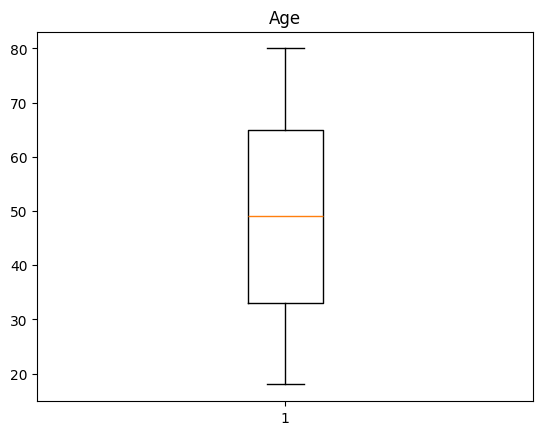

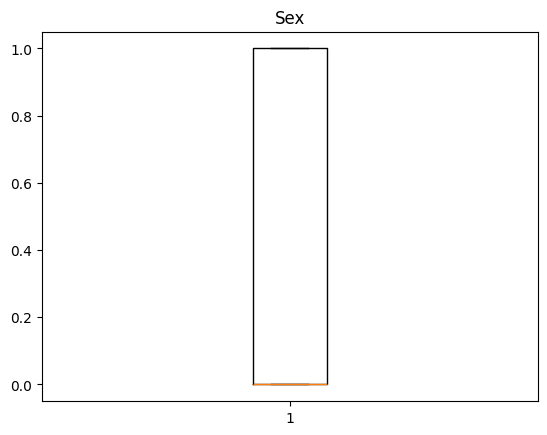

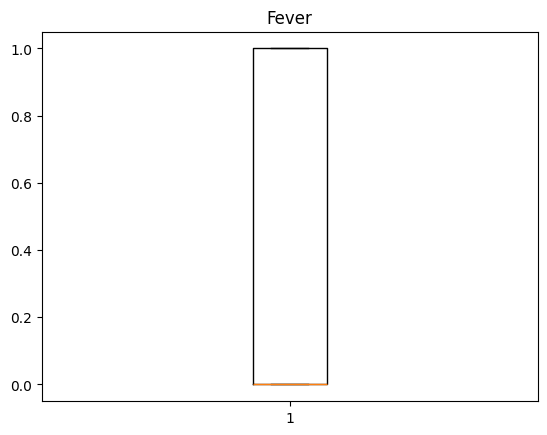

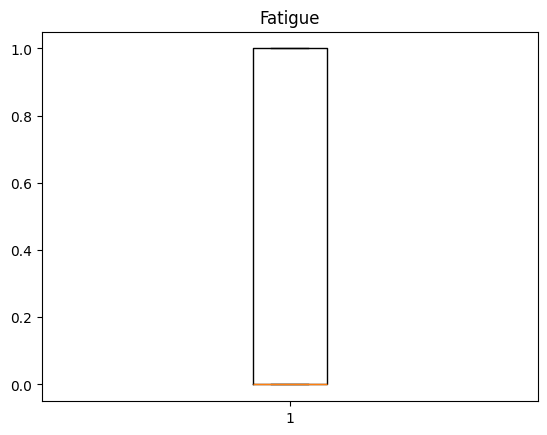

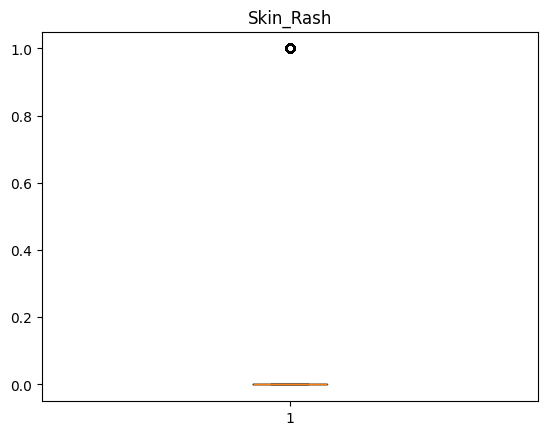

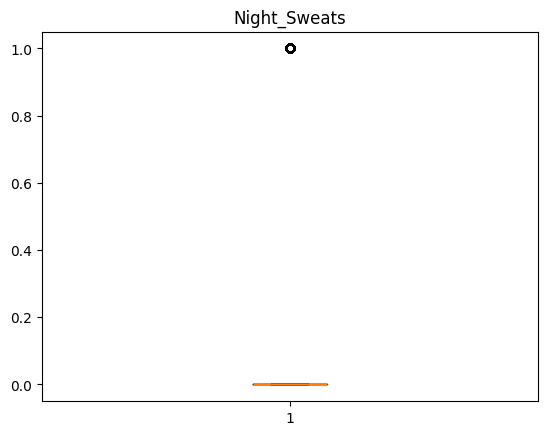

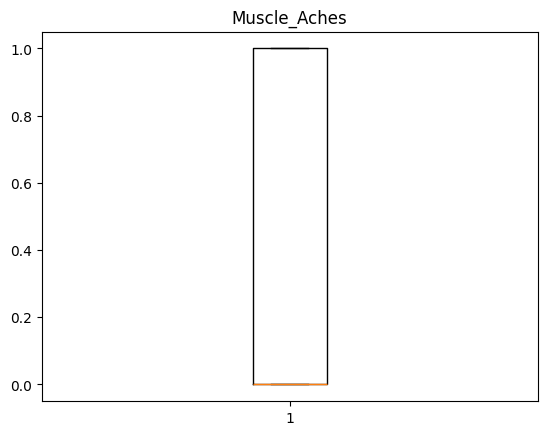

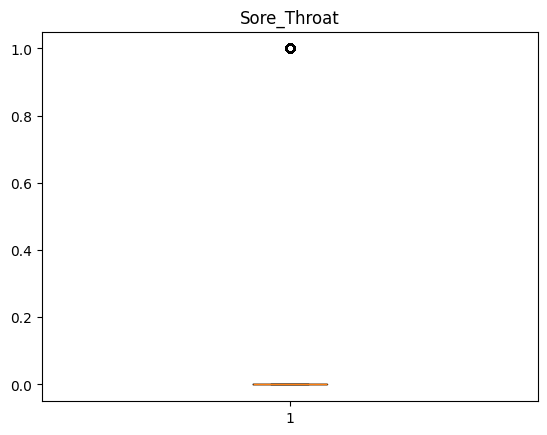

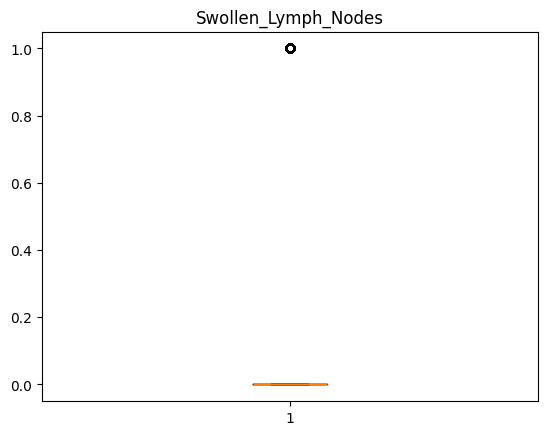

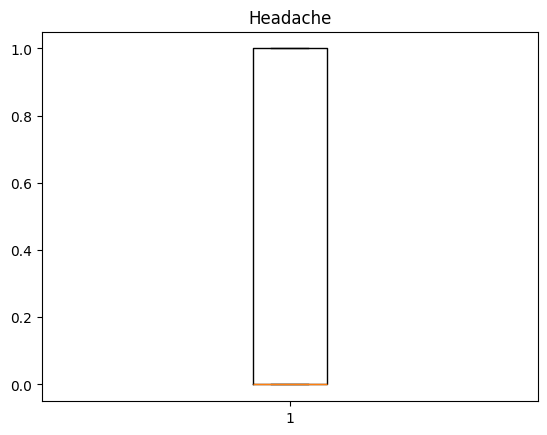

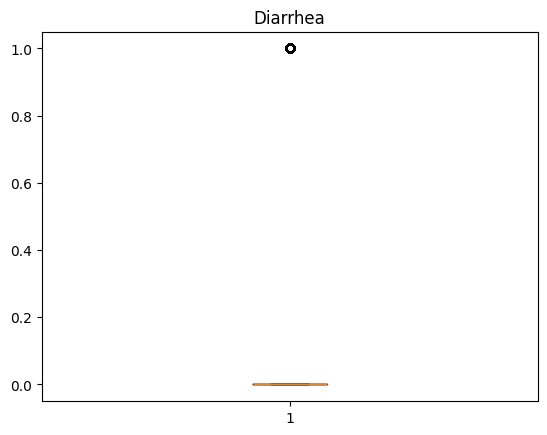

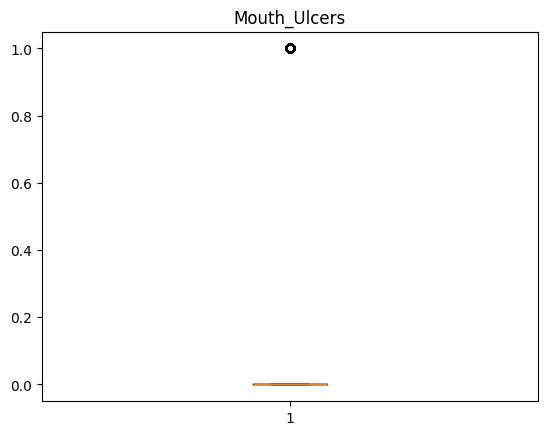

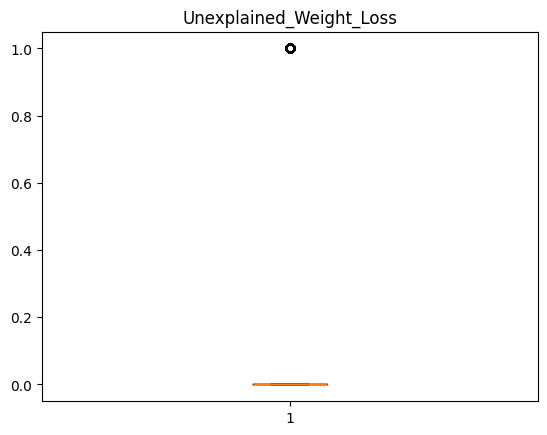

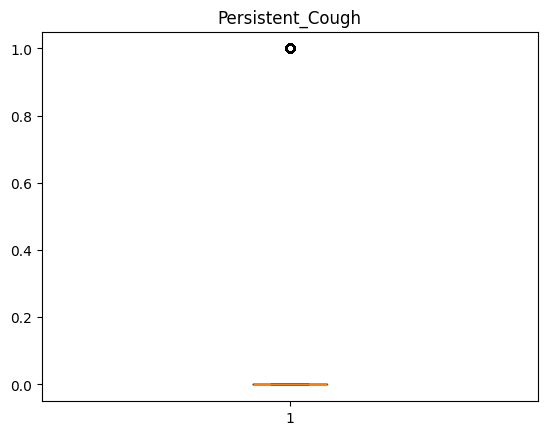

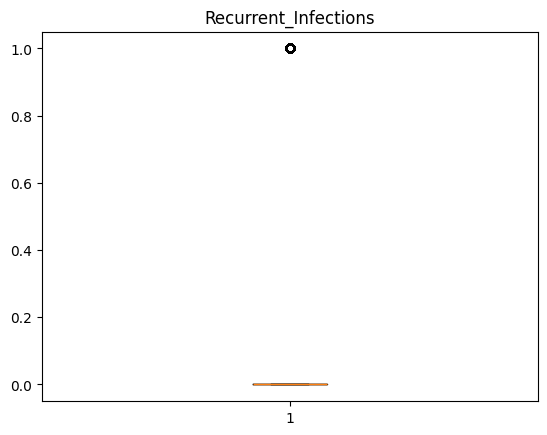

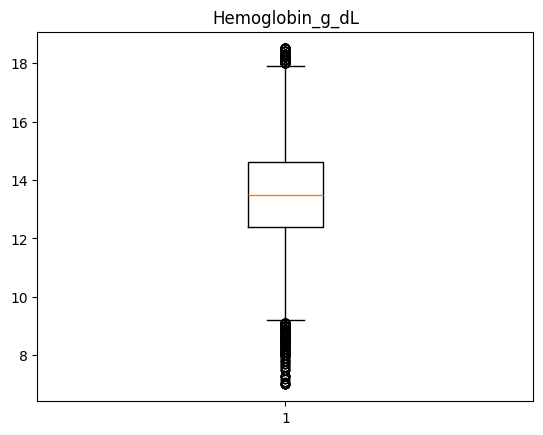

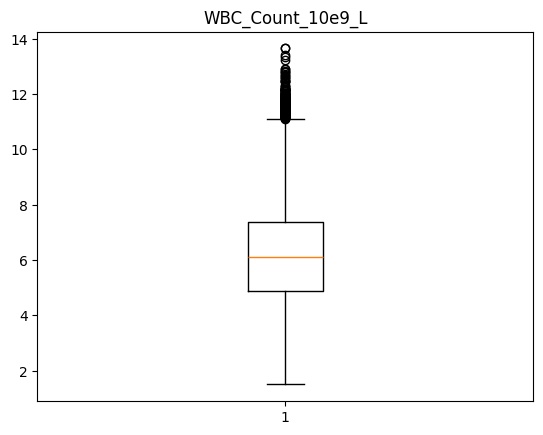

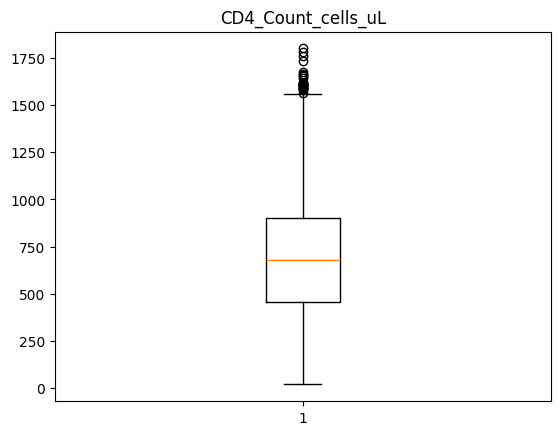

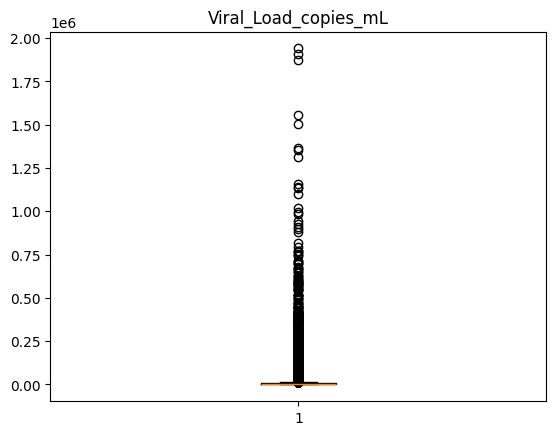

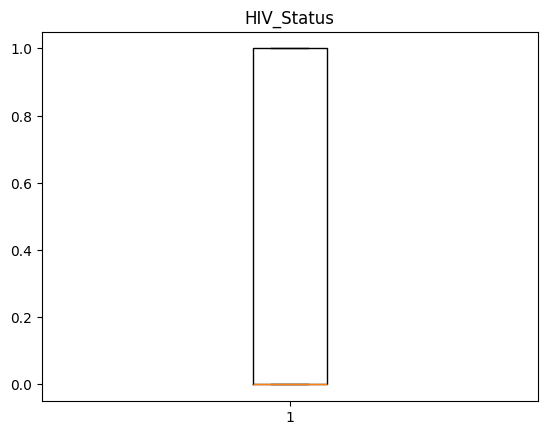

In [89]:
for col in df.columns:
    plt.title(col)
    plt.boxplot(df[col])
    plt.show()

In [90]:
df.corr()

,Age,Sex,Fever,Fatigue,Skin_Rash,Night_Sweats,Muscle_Aches,Sore_Throat,Swollen_Lymph_Nodes,Headache,Diarrhea,Mouth_Ulcers,Unexplained_Weight_Loss,Persistent_Cough,Recurrent_Infections,Hemoglobin_g_dL,WBC_Count_10e9_L,CD4_Count_cells_uL,Viral_Load_copies_mL,HIV_Status
Age,1.000000,-0.002452,-0.006416,0.002325,-0.003486,0.005346,-0.002652,-0.000145,-0.003055,-0.003605,0.006032,-0.002385,0.000868,0.001819,0.001268,-0.004495,-0.003755,-0.009315,0.003695,0.002188
Sex,-0.002452,1.000000,0.000024,0.001853,0.004030,0.002477,-0.004939,-0.002941,-0.000763,0.002037,-0.003022,0.006040,-0.001839,-0.000166,-0.001338,-0.000690,-0.000322,-0.001108,-0.002975,0.001029
Fever,-0.006416,0.000024,1.000000,0.072808,0.040067,0.064159,0.049534,0.027730,0.070148,0.025982,0.051241,0.050282,0.066882,0.030141,0.076244,-0.061897,-0.086085,-0.179908,0.082583,0.261232
Fatigue,0.002325,0.001853,0.072808,1.000000,0.043842,0.061012,0.032041,0.035346,0.073082,0.025941,0.058292,0.054166,0.072670,0.034243,0.079155,-0.067010,-0.081571,-0.189539,0.087522,0.273362
Skin_Rash,-0.003486,0.004030,0.040067,0.043842,1.000000,0.042178,0.024101,0.021037,0.046602,0.014198,0.033776,0.033103,0.042198,0.028929,0.045869,-0.034464,-0.043203,-0.106777,0.046585,0.161730
Night_Sweats,0.005346,0.002477,0.064159,0.061012,0.042178,1.000000,0.040944,0.029713,0.064689,0.021915,0.043128,0.039827,0.064992,0.024499,0.069513,-0.051060,-0.069379,-0.154511,0.083334,0.230905
Muscle_Aches,-0.002652,-0.004939,0.049534,0.032041,0.024101,0.040944,1.000000,0.018534,0.046034,0.020966,0.035431,0.028030,0.045615,0.021160,0.050999,-0.033956,-0.055012,-0.119647,0.050728,0.168611
Sore_Throat,-0.000145,-0.002941,0.027730,0.035346,0.021037,0.029713,0.018534,1.000000,0.035465,0.011403,0.027600,0.026224,0.030875,0.012152,0.037568,-0.032874,-0.031766,-0.086044,0.047760,0.125383
Swollen_Lymph_Nodes,-0.003055,-0.000763,0.070148,0.073082,0.046602,0.064689,0.046034,0.035465,1.000000,0.018592,0.058225,0.045900,0.075236,0.036025,0.080797,-0.064589,-0.081066,-0.188283,0.092601,0.269612
Headache,-0.003605,0.002037,0.025982,0.025941,0.014198,0.021915,0.020966,0.011403,0.018592,1.000000,0.024194,0.024791,0.031492,0.014531,0.039274,-0.023572,-0.032579,-0.076917,0.036272,0.110396


In [9]:
x = df.drop('HIV_Status',axis=1)

In [92]:
y = df['HIV_Status']

In [93]:
y.value_counts()

HIV_Status
0    30000
1    20000
Name: count, dtype: int64

In [94]:
x_train,x_test,y_train,y_test = train_test_split(x,y,stratify=y,random_state=42,test_size=0.2)

In [98]:
smt = SMOTETomek(random_state=42)
x_train,y_train = smt.fit_resample(x_train,y_train)

In [99]:
y_train.value_counts()

HIV_Status
0    23537
1    23537
Name: count, dtype: int64

In [100]:
knn2 = KNeighborsClassifier(n_neighbors=13)
knn2.fit(x_train,y_train)
knn_pred2 = knn2.predict(x_test)
print(classification_report(y_test,knn_pred2))
confusion_matrix(y_test,knn_pred2)

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      6000
           1       0.93      0.92      0.92      4000

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



array([[5717,  283],
       [ 315, 3685]])

In [101]:
tree2 = DecisionTreeClassifier(min_samples_split=7)
tree2.fit(x_train,y_train)
pred2 = tree2.predict(x_test)
print(classification_report(y_test,pred2))
confusion_matrix(y_test,pred2)

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      6000
           1       0.92      0.92      0.92      4000

    accuracy                           0.94     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.94      0.94      0.94     10000



array([[5689,  311],
       [ 328, 3672]])

In [102]:
random2 = RandomForestClassifier(n_estimators=300,min_samples_split=5)
random2.fit(x_train,y_train)
random_pred2 = random2.predict(x_test)
print(classification_report(y_test,random_pred2))
print(confusion_matrix(y_test,random_pred2))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      6000
           1       0.95      0.95      0.95      4000

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000

[[5806  194]
 [ 210 3790]]


In [105]:
train_pred = random2.predict(x_train)
print(classification_report(y_train,train_pred))
print(confusion_matrix(y_train,train_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00     23537
           1       1.00      0.99      1.00     23537

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074

[[23505    32]
 [  132 23405]]


In [106]:
dump(random2,"HIV_model.joblib")

['HIV_model.joblib']

In [12]:
x.columns

Index(['Age', 'Sex', 'Fever', 'Fatigue', 'Skin_Rash', 'Night_Sweats',
       'Muscle_Aches', 'Sore_Throat', 'Swollen_Lymph_Nodes', 'Headache',
       'Diarrhea', 'Mouth_Ulcers', 'Unexplained_Weight_Loss',
       'Persistent_Cough', 'Recurrent_Infections', 'Hemoglobin_g_dL',
       'WBC_Count_10e9_L', 'CD4_Count_cells_uL', 'Viral_Load_copies_mL'],
      dtype='object')